# Thick Sample Ptychography Forward Model Tutorial 2D

This tutorial demonstrates how to use `thick_ptycho` to set up and solve a 2D forward problem with multiple probes, both iteratively and as a full system.


The forward model solves the paraxial equation:

\begin{equation}
\frac{\partial u}{\partial z} = a \frac{\partial^2 u}{\partial x^2}  + C(x, z) u,
\end{equation}
where
\begin{equation}
a := \frac{1}{2ik} \qquad \text{and} \qquad C(x, z) := \frac{k}{2i} \left(n^2(x, z) - 1\right)
\end{equation}


**$n$ defines the refractive index of the volume. $k$ is the wave number.**

### 1. Import Libraries: Sample Space and Forward Model


In [1]:
from thick_ptycho.simulation.config import SimulationConfig, ProbeType, ProbeConfig
from thick_ptycho.simulation.scan_frame import Limits
from thick_ptycho.simulation.simulation_space import create_simulation_space
from thick_ptycho.simulation.ptycho_object import create_ptycho_object
from thick_ptycho.simulation.ptycho_probe import create_ptycho_probes
from thick_ptycho.forward_model import PWEPetscFullPinTSolver
import os


import time
import numpy as np


from utils import plot_solution, create_random_circle_object, plot_probes, plot_data

### 2. Create Simulated Sample and Space

Choose boundary conditions, probe type, and define the spatial domain and discretization.

In [2]:
probe_config = ProbeConfig(
    type=ProbeType.AIRY_DISK,
    wave_length=6.35e-7,  # meters (0.635 μm). Visible light
    diameter=5e-6,  # [m]
    focus=-5e-6,  # focal length [m]
)
n_medium = 1.0  # Refractive index of surrounding medium

In [3]:
# Width Discretization (Pixels)
scan_points = 120
step_size_px = 10  # Resolution
pad_factor = 1.5  # Must be >= 1.0
# Overlap = N - (scan_points*step_size_px) = padding
# Overlap factor = (N - (scan_points*step_size_px)) / step_size_px
#                = (pad_factor*scan_points) - scan_points) = scan_points*(pad_factor - 1)
# N = int(pad_factor*scan_points*step_size_px)
solve_reduced_domain = True

# Thickness Discretization (Pixels)
points_per_wavelength = 4  # Points per Wavelength for Parallel Wave Equation Solver
# nz = 50  # Slices for Multi-Slice
# Then:
#  - dz = wavelength / points_per_wavelength
#  - nz = int((zlims[1] - zlims[0]) / dz)
# Override by setting nz directly


# --- Simulation spatial dimensions (in meters) ---
spatial_limits = Limits(
    x=(0.0, 150e-6),  # Sample width
    z=(0.0, 150e-6),  # Sample thickness
    units="meters",
)

In [ ]:
# --- Create the SimulationConfig object ---
# Defines scan path, probe parameters, discretization,
# object domain.
# Solver parameters are defined in the solver classes.
sim_config = SimulationConfig(
    probe_config=probe_config,
    # Spatial discretization
    scan_points=scan_points,
    step_size_px=step_size_px,
    pad_factor=pad_factor,
    solve_reduced_domain=solve_reduced_domain,
    points_per_wavelength=points_per_wavelength,
    spatial_limits=spatial_limits,
    # Refractive index or Transmission Function Constant Surrounding Medium
    medium=n_medium,  # 1.0 for free space
    # Logging and results
    results_dir="./results",
    use_logging=True,
    empty_space_px=600,
)

# --- Create the simulation space ---
simulation_space = create_simulation_space(sim_config)
simulation_space.summarize()
print("Padding/Overlap:", simulation_space.nx - simulation_space.min_nx)

2025-12-19 23:02:35,811 - INFO - === Scan Summary ===
2025-12-19 23:02:35,812 - INFO -   Sample space (x-range): 1.500e-04 m
2025-12-19 23:02:35,813 - INFO -   Sample space (z-range): 1.500e-04 m


2025-12-19 23:02:35,815 - INFO -   Sample Pixels:          1801 px
2025-12-19 23:02:35,816 - INFO -   Step size:              10 px
2025-12-19 23:02:35,817 - INFO -   Number of scan points:  120
2025-12-19 23:02:35,818 - INFO -   Steps in z:             944
2025-12-19 23:02:35,820 - INFO -   Solve reduced domain:   610 px
2025-12-19 23:02:35,822 - INFO -   Max Overlap Pixels:     601 px
2025-12-19 23:02:35,823 - INFO -   Probe diameter:         5.000e-06 m
2025-12-19 23:02:35,824 - INFO -   Probe Pixels:           60 px
2025-12-19 23:02:35,825 - INFO -   Max Overlap:            4.167e-06 m
2025-12-19 23:02:35,826 - INFO -   Percentage Overlap:     83.33%



Padding/Overlap: 601


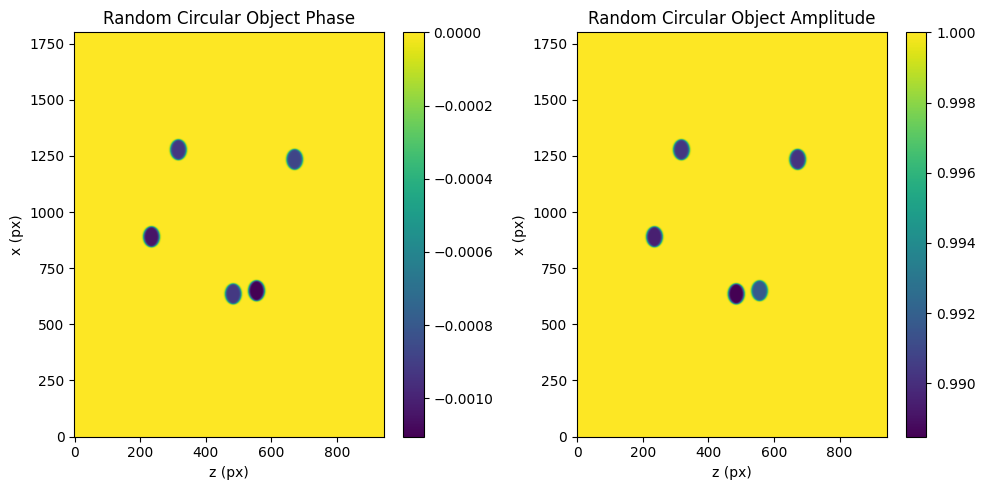

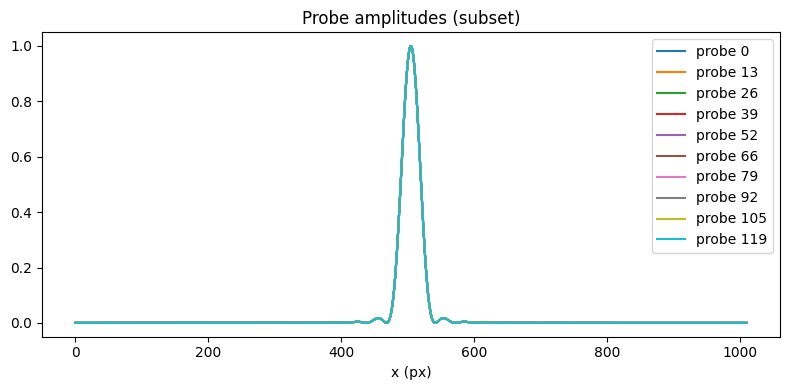

In [5]:
ptycho_object = create_ptycho_object(simulation_space)

ptycho_object = create_random_circle_object(
    simulation_space, ptycho_object, num_circles=5
)


# --- Create a set of Simulated Ptycho Probes (not dependent on number of slices/steps) ---
ptycho_probes = create_ptycho_probes(simulation_space)

plot_probes(simulation_space, ptycho_probes)

### 3. Generate Data with Fine nz Discretization

Solution is a complex propagated field, shape:

(num_projections, num_angles, num_probes, nx[,ny], nz).

In [6]:
# Solve Full Space Space, Iterative
# --- Create Forward Model ---
time_start = time.time()
forward_model_pwe = PWEPetscFullPinTSolver(
    simulation_space,
    ptycho_probes,
    bc_type="impedance",
    alpha=1e-8,
    atol=1e-4,
    verbose=True,
)

# Iterative solution
u_fine = forward_model_pwe.solve(n=ptycho_object.refractive_index)
time_end = time.time()
print(
    f"Forward model creation and solving time: {time_end - time_start:.2f} seconds.\n"
)
data_ew = forward_model_pwe.get_exit_waves(u_fine)
data = forward_model_pwe.get_farfield_intensities(
    exit_waves=data_ew, poisson_noise=False
)

Setting up PETSc system...
PETSc system setup time: 0.03 seconds.
Solving with PETSc GMRES...
  Iter   0 | Residual: 4.811e+00
Pre-factorizing PiT preconditioner blocks for mode 'forward'...
PiT preconditioner block factorization time: 1.05 seconds.

  Iter   1 | Residual: 3.844e-02
  Iter   2 | Residual: 5.017e-03
  Iter   3 | Residual: 3.631e-04
  Iter   4 | Residual: 1.881e-05
PETSc GMRES solve time: 2.17 s
Time: 2.17 s. Iters: 4. Reason: 3
[PWEPetscFullPinTSolver] solved probe 1/120 at angle _idx 0 in 2.26s
Setting up PETSc system...
PETSc system setup time: 0.02 seconds.
Solving with PETSc GMRES...
  Iter   0 | Residual: 3.485e-02
  Iter   1 | Residual: 5.853e-03
  Iter   2 | Residual: 6.853e-04
  Iter   3 | Residual: 6.270e-05
PETSc GMRES solve time: 1.01 s
Time: 1.01 s. Iters: 3. Reason: 3
[PWEPetscFullPinTSolver] solved probe 2/120 at angle _idx 0 in 1.08s
Setting up PETSc system...
PETSc system setup time: 0.02 seconds.
Solving with PETSc GMRES...
  Iter   0 | Residual: 3.770e

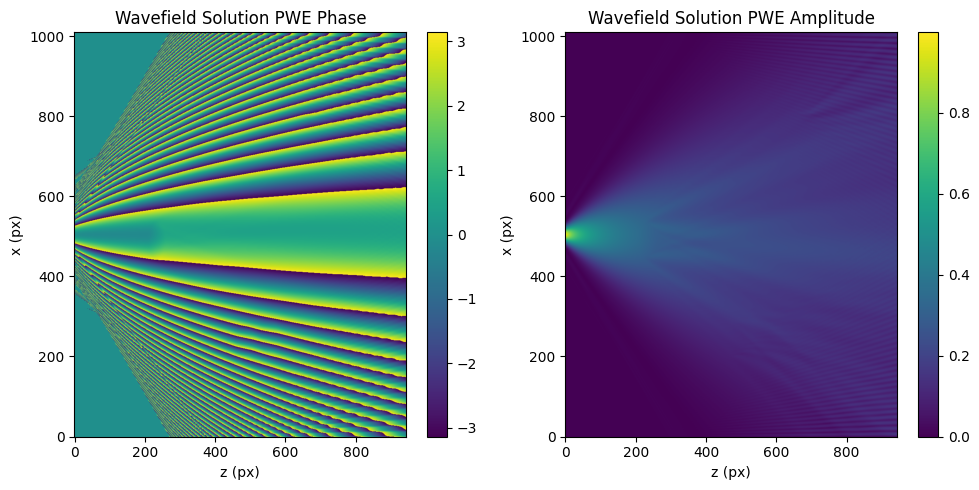

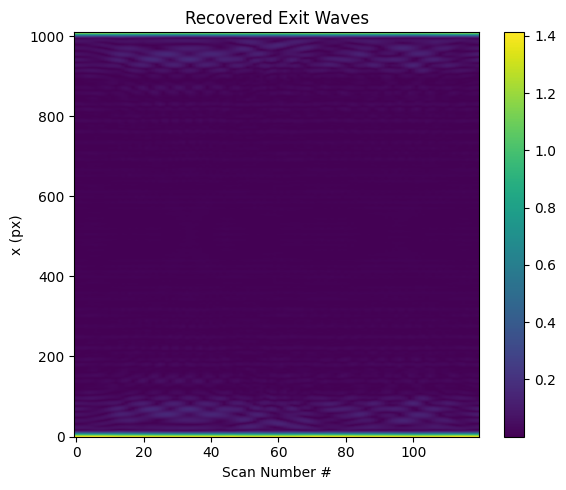

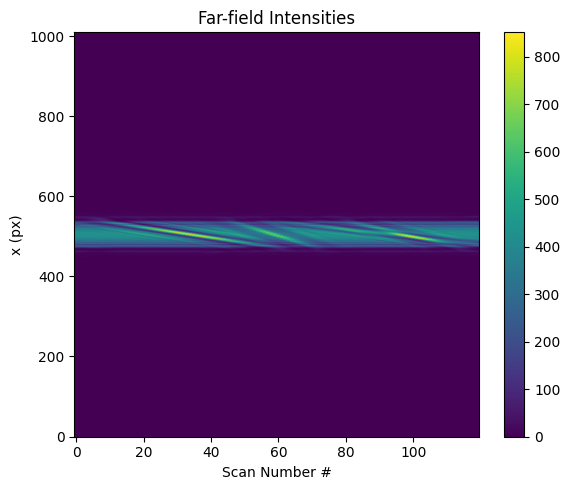

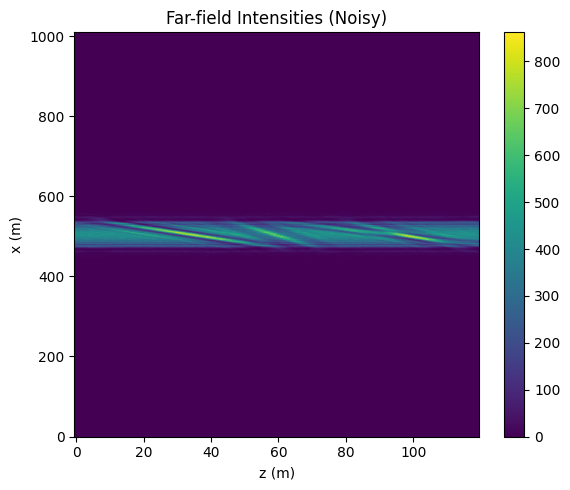

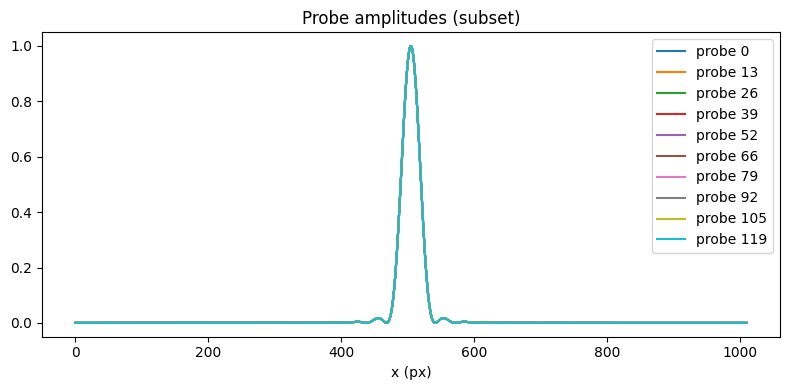

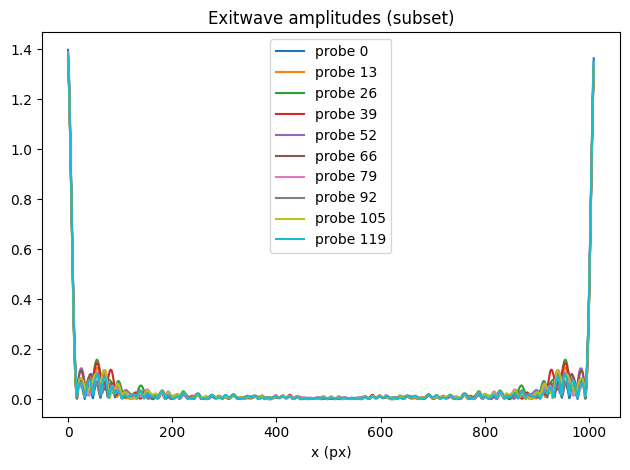

In [7]:
plot_solution(simulation_space, solution=u_fine)
plot_data(simulation_space, data=data, probes=ptycho_probes)

In [8]:
# import pickle
from dataclasses import asdict

np.savez_compressed(
    os.path.join("./results", "padded_simulated_data_petsc.npz"),
    sim_config=asdict(sim_config),
    exit_waves=data_ew,
    ref_index=ptycho_object.refractive_index,
)

In [9]:
# Solve Full Space Space, Iterative
# --- Create Forward Model ---
time_start = time.time()
forward_model_pwe = PWEPetscFullPinTSolver(
    simulation_space,
    ptycho_probes,
    bc_type="impedance",
    alpha=1e-8,
    atol=1e-4,
    verbose=True,
)

# Iterative solution
u_fine_free_space = forward_model_pwe.solve(
    n=np.ones_like(ptycho_object.refractive_index)
)
time_end = time.time()
print(
    f"Forward model creation and solving time: {time_end - time_start:.2f} seconds.\n"
)

Setting up PETSc system...
PETSc system setup time: 0.09 seconds.
Solving with PETSc GMRES...
  Iter   0 | Residual: 4.811e+00
Pre-factorizing PiT preconditioner blocks for mode 'forward'...
PiT preconditioner block factorization time: 1.13 seconds.

  Iter   1 | Residual: 4.174e-07
PETSc GMRES solve time: 1.47 s
Time: 1.47 s. Iters: 1. Reason: 3
[PWEPetscFullPinTSolver] solved probe 1/120 at angle _idx 0 in 1.67s
Setting up PETSc system...
PETSc system setup time: 0.04 seconds.
Solving with PETSc GMRES...
  Iter   0 | Residual: 4.130e-07
PETSc GMRES solve time: 0.10 s
Time: 0.10 s. Iters: 0. Reason: 3
[PWEPetscFullPinTSolver] solved probe 2/120 at angle _idx 0 in 0.19s
Setting up PETSc system...
PETSc system setup time: 0.03 seconds.
Solving with PETSc GMRES...
  Iter   0 | Residual: 4.130e-07
PETSc GMRES solve time: 0.13 s
Time: 0.13 s. Iters: 0. Reason: 3
[PWEPetscFullPinTSolver] solved probe 3/120 at angle _idx 0 in 0.22s
Setting up PETSc system...
PETSc system setup time: 0.02 sec

In [10]:
# import pickle
from dataclasses import asdict

data_ew_free_space = forward_model_pwe.get_exit_waves(u_fine_free_space)
data_free_space = forward_model_pwe.get_farfield_intensities(
    exit_waves=data_ew_free_space, poisson_noise=False
)
# np.savez_compressed(
#     os.path.join("./results", "padded_simulated_data_petsc_free_space.npz"),
#     sim_config=asdict(sim_config),
#     exit_waves=data_ew_free_space,
#     ref_index=ptycho_object.refractive_index,
# )

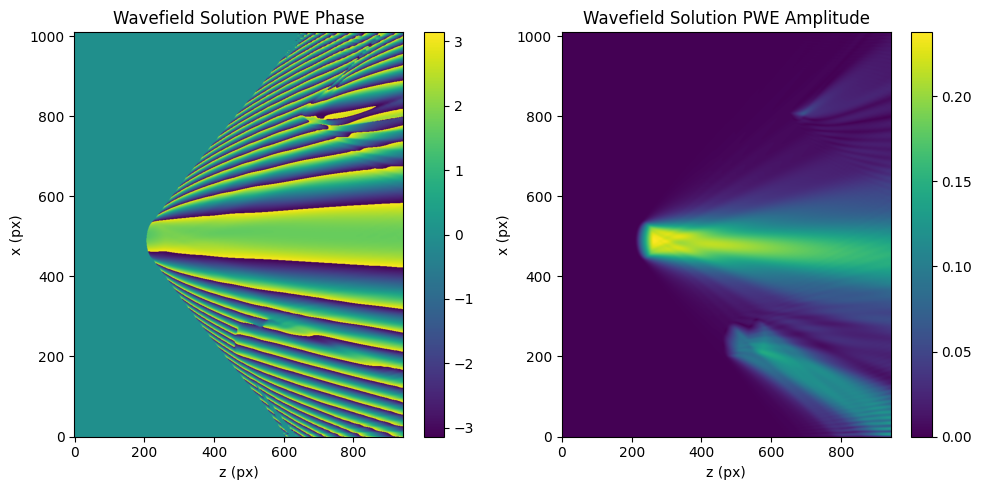

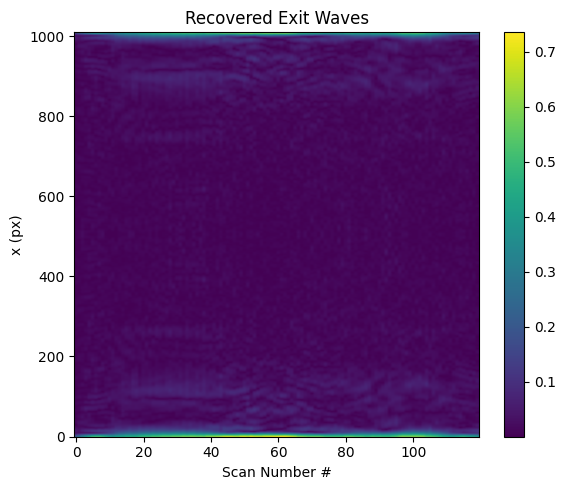

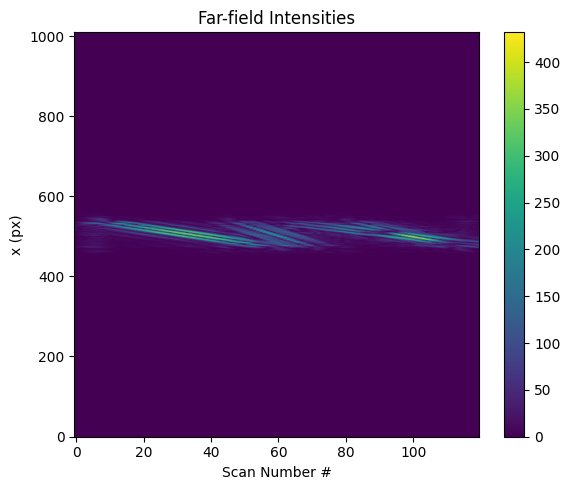

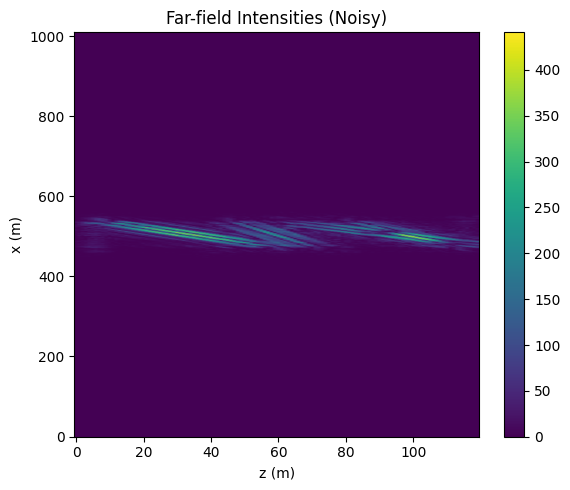

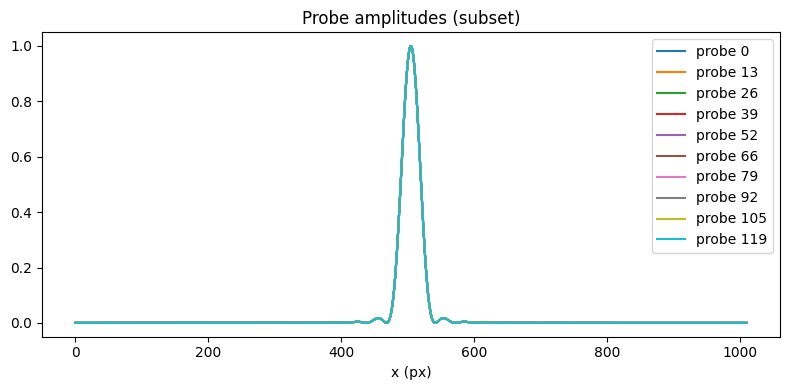

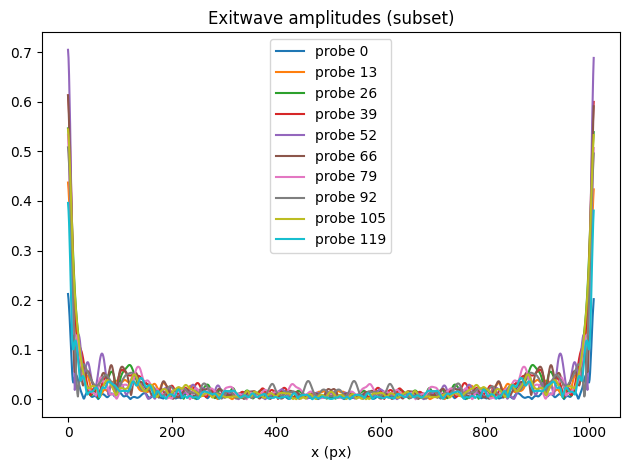

In [13]:
plot_solution(simulation_space, solution=u_fine - u_fine_free_space)
plot_data(
    simulation_space,
    data=np.abs(data - data_free_space),
    probes=ptycho_probes,
)
exitwaves=data_ew - data_ew_free_space

## Verify Amplitude Of Exitwave can be Recovered From Intensity

(120, 1010)
RMS Intensity Error: 84.7992
Theoretical Noise Level (sqrt(mean)): 84.3338
Error Difference: 0.4654


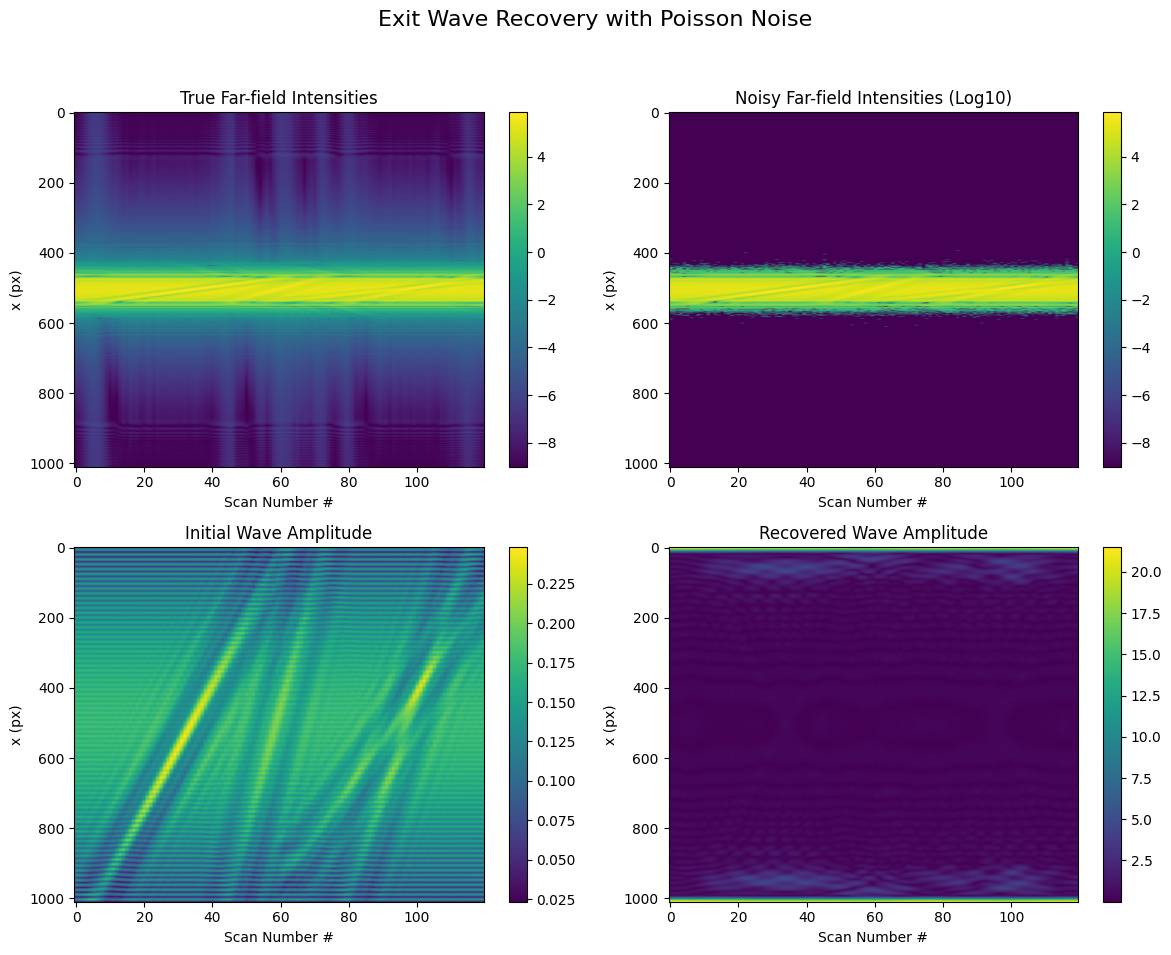

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print(data_ew.shape)
# 1. Generate Noiseless Fourier Domain
# FFT along the scan axis (axis=-1)
fft_true = np.fft.fftshift(np.fft.fft(data_ew, axis=-1), axes=-1)
intensities_true = np.abs(fft_true)**2

# 2. Add Poisson Noise to simulating a real detector
# The mean of the Poisson distribution is the true intensity
intensities_noisy = np.random.poisson(intensities_true).astype(float)

# 3. Recover Wave Amplitude from Noisy Data
# In a real phase retrieval scenario, we keep the original phase
phase_estimate = np.angle(fft_true)
fmodel_updated = np.sqrt(intensities_noisy) * np.exp(1j * phase_estimate)

# Inverse FFT back to spatial domain
amp_recovered = np.fft.ifft(np.fft.ifftshift(fmodel_updated, axes=-1), axis=-1)

# 4. Error Metrics
# Residual difference between noisy and true intensities
intensity_diff = intensities_noisy - intensities_true
rms_error = np.sqrt(np.mean(intensity_diff**2))
theoretical_noise = np.sqrt(np.mean(intensities_true))

print(f"RMS Intensity Error: {rms_error:.4f}")
print(f"Theoretical Noise Level (sqrt(mean)): {theoretical_noise:.4f}")
print(f"Error Difference: {np.abs(theoretical_noise - rms_error):.4f}")
if np.abs(theoretical_noise - rms_error) < 1e-1:
    print("RMS error is within theoretical noise limits.")

# 5. Visualization
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Exit Wave Recovery with Poisson Noise', fontsize=16)

# Top Left: Initial Wave Amplitude
im0 = axes[1, 0].imshow(np.abs(data_ew).T, aspect='auto', cmap='viridis')
axes[1, 0].set_title('Initial Wave Amplitude')
fig.colorbar(im0, ax=axes[1, 0])

# Top Right: Noisy Far-field Intensities
im1 = axes[0, 1].imshow(np.log10(intensities_noisy + 1e-9).T, aspect='auto', cmap='viridis')
axes[0, 1].set_title('Noisy Far-field Intensities (Log10)')
fig.colorbar(im1, ax=axes[0, 1])

# Bottom Left: Recovered Wave Amplitude (from noisy data)
im2 = axes[0, 0].imshow(np.log10(intensities_true + 1e-9).T, aspect='auto', cmap='viridis')
axes[0, 0].set_title('True Far-field Intensities')
fig.colorbar(im2, ax=axes[0, 0])

# Bottom Right: Spatial Amplitude Error
# This shows where the noise affects the spatial domain most
im3 = axes[1, 1].imshow(np.abs(amp_recovered).T, aspect='auto', cmap='viridis')
axes[1, 1].set_title('Recovered Wave Amplitude')
fig.colorbar(im3, ax=axes[1, 1])

for ax in axes.flat:
    ax.set_xlabel('Scan Number #')
    ax.set_ylabel('x (px)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()